In [1]:
import matplotlib.pyplot as plt
import numpy as np

import sys
sys.path.append("/home/murray/Projects/psaap-active-learning")  # For home laptop env

from src.problems.psaap_example import get_HF_probs, get_LF_probs, load_all_lf_data, load_all_hf_data
from src.problems.toy_example import create_smooth_change_linear, create_smooth_change_nonlinear

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:14<00:00,  6.77it/s]


In [ ]:
linear_low_f1, linear_high_f1, p_LF_toy, p_HF_toy = create_smooth_change_linear()

Y_linear_low_grid, p_LF = linear_low_f1(X_test, reps=1)
Y_linear_high_grid, p_HF = linear_high_f1(X_test, reps=1)

p_HF = p_HF.reshape((100, 100))
p_LF = p_LF.reshape((100, 100))


fig, axs = plt.subplots(1, 2, figsize=(5, 2), dpi=200)

# Define contour levels from 0.2 to 0.8 in steps of 0.2
contour_levels = np.arange(0.2, 1.0, 0.2)

# --- Plot for High Fidelity (HF) ---
# Use vmin and vmax to set the colorbar range from 0 to 1
im_hf = axs[0].imshow(p_HF, origin="lower", vmin=0, vmax=1, extent=[0, 1, 0, 1])
# Add contour lines
axs[0].contour(p_HF, levels=contour_levels, colors='white', linewidths=0.5, extent=[0, 1, 0,1 ])
# Add the colorbar
fig.colorbar(im_hf, ax=axs[0], label="$P(Y_{HF}=1)$")

axs[0].set_title("HF")
axs[0].set_xticks([0, 0.5, 1])
axs[0].set_yticks([0, 0.5, 1])


# --- Plot for Low Fidelity (LF) ---
# Use vmin and vmax to set the colorbar range from 0 to 1
im_lf = axs[1].imshow(p_LF, origin="lower", vmin=0, vmax=1, extent=[0, 1, 0, 1])
# Add contour lines
axs[1].contour(p_LF, levels=contour_levels, colors='white', linewidths=0.5, extent=[0, 1, 0, 1])
# Add the colorbar
fig.colorbar(im_lf, ax=axs[1], label="$P(Y_{LF}=1)$")

axs[1].set_title("LF")
axs[1].set_xticks([0, 0.5, 1])
axs[1].set_yticks([0, 0.5, 1])

fig.tight_layout()

# Save the figure as a PDF before showing it
# Use bbox_inches='tight' to minimize whitespace around the figure
plt.savefig("toy_problem_linear.pdf", bbox_inches='tight')

plt.show()


In [ ]:
linear_low_f1, linear_high_f1, p_LF_toy, p_HF_toy = create_smooth_change_nonlinear()

Y_linear_low_grid, p_LF = linear_low_f1(X_test, reps=1)
Y_linear_high_grid, p_HF = linear_high_f1(X_test, reps=1)

p_HF = p_HF.reshape((100, 100))
p_LF = p_LF.reshape((100, 100))

fig, axs = plt.subplots(1, 2, figsize=(5, 2), dpi=200)

# Define contour levels from 0.2 to 0.8 in steps of 0.2
contour_levels = np.arange(0.2, 1.0, 0.2)

# --- Plot for High Fidelity (HF) ---
# Use vmin and vmax to set the colorbar range from 0 to 1
im_hf = axs[0].imshow(p_HF, origin="lower", vmin=0, vmax=1, extent=[0, 1, 0, 1])
# Add contour lines
axs[0].contour(p_HF, levels=contour_levels, colors='white', linewidths=0.5, extent=[0, 1, 0,1 ])
# Add the colorbar
fig.colorbar(im_hf, ax=axs[0], label="$P(Y_{HF}=1)$")

axs[0].set_title("HF")
axs[0].set_xticks([0, 0.5, 1])
axs[0].set_yticks([0, 0.5, 1])


# --- Plot for Low Fidelity (LF) ---
# Use vmin and vmax to set the colorbar range from 0 to 1
im_lf = axs[1].imshow(p_LF, origin="lower", vmin=0, vmax=1, extent=[0, 1, 0, 1])
# Add contour lines
axs[1].contour(p_LF, levels=contour_levels, colors='white', linewidths=0.5, extent=[0, 1, 0, 1])
# Add the colorbar
fig.colorbar(im_lf, ax=axs[1], label="$P(Y_{LF}=1)$")

axs[1].set_title("LF")
axs[1].set_xticks([0, 0.5, 1])
axs[1].set_yticks([0, 0.5, 1])

fig.tight_layout()

# Save the figure as a PDF before showing it
# Use bbox_inches='tight' to minimize whitespace around the figure
plt.savefig("toy_problem_nonlinear.pdf", bbox_inches='tight')

plt.show()


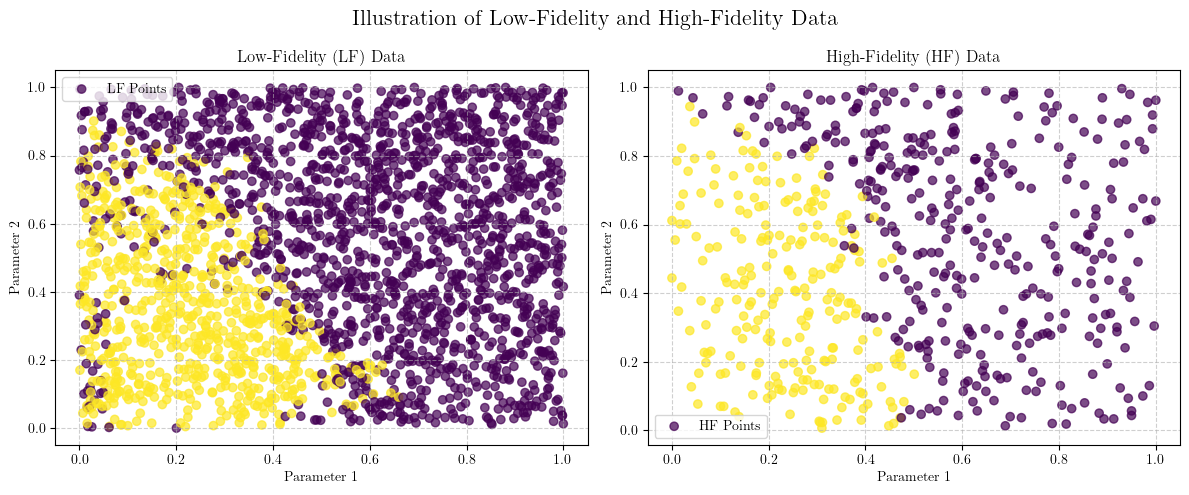

(2361, 2)
(600, 2)


In [8]:
# Illustrate the LF and HF data

X_lf, Y_lf = load_all_lf_data()  # (N, 2)
X_hf, Y_hf = load_all_hf_data()

# Plot these points, on side by side axes
# Create a figure and a set of subplots (1 row, 2 columns)
# figsize controls the overall size of the figure
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# --- Plot 1: Low-Fidelity Data ---
# Plot on the first axes object (axes[0])
axes[0].scatter(X_lf[:, 0], X_lf[:, 1], c=Y_lf, alpha=0.7, label='LF Points')
axes[0].set_title('Low-Fidelity (LF) Data')
axes[0].set_xlabel('Parameter 1')
axes[0].set_ylabel('Parameter 2')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# --- Plot 2: High-Fidelity Data ---
# Plot on the second axes object (axes[1])
axes[1].scatter(X_hf[:, 0], X_hf[:, 1], c=Y_hf, alpha=0.7, label='HF Points')
axes[1].set_title('High-Fidelity (HF) Data')
axes[1].set_xlabel('Parameter 1')
axes[1].set_ylabel('Parameter 2')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

# Add a main title for the entire figure
fig.suptitle('Illustration of Low-Fidelity and High-Fidelity Data', fontsize=16)

# Adjust layout to prevent titles and labels from overlapping
plt.tight_layout()

# Display the final plot
plt.show()

print(X_lf.shape)
print(X_hf.shape)

In [ ]:
xs = np.linspace(0, 1, 100)
ys = np.linspace(0, 1, 100)
X, Y = np.meshgrid(xs, ys)
X_test = np.stack([X.ravel(), Y.ravel()], axis=-1)
p_HF = get_HF_probs(X_test).reshape((100, 100))
p_LF = get_LF_probs(X_test).reshape((100, 100))


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(5, 2), dpi=200)

im = axs[0].imshow(p_HF, origin="lower")
fig.colorbar(im, ax=axs[0], label="$P(Y_{HF}=1)$")
im = axs[1].imshow(p_LF, origin="lower")
fig.colorbar(im, ax=axs[1], label="$P(Y_{LF}=1)$")

axs[0].set_title("HF")
axs[1].set_title("LF")
axs[0].set_xticks([])
axs[0].set_yticks([])
axs[1].set_xticks([])
axs[1].set_yticks([])

plt.show()